In [1]:
# ==========================================
# IRIS FLOWER CLASSIFICATION PROJECT
# STEP 1: IMPORT LIBRARIES
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")
print("Ready to start Iris Classification.")

All libraries imported successfully!
Ready to start Iris Classification.


In [2]:
# ==========================================
# STEP 2: LOAD IRIS DATASET
# ==========================================

# Load the Iris dataset
iris = load_iris()

# Convert dataset into a Pandas DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Add the species column
df["species"] = iris.target

# Display first five records
print("First five rows of Iris dataset:")
print(df.head())

# Display dataset shape
print("\nDataset shape:")
print(df.shape)

print("\nDataset loaded successfully!")

First five rows of Iris dataset:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  

Dataset shape:
(150, 5)

Dataset loaded successfully!


In [3]:
# ==========================================
# STEP 3: DATA ANALYSIS AND MISSING VALUES
# ==========================================

# 1. Display first five rows
print("FIRST FIVE ROWS:")
print(df.head())

# 2. Display last five rows
print("\nLAST FIVE ROWS:")
print(df.tail())

# 3. Check dataset information
print("\nDATASET INFORMATION:")
df.info()

# 4. Check number of rows and columns
print("\nDATASET SHAPE:")
print(df.shape)

# 5. Statistical analysis
print("\nSTATISTICAL DESCRIPTION:")
print(df.describe())

# 6. Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# 7. Check duplicate records
print("\nDUPLICATE RECORDS:")
print(df.duplicated().sum())

# 8. Check species distribution
print("\nSPECIES DISTRIBUTION:")
print(df["species"].value_counts())

print("\nDATA ANALYSIS COMPLETED SUCCESSFULLY!")

FIRST FIVE ROWS:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  

LAST FIVE ROWS:
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
145                6.7               3.0                5.2               2.3   
146                6.3               2.5                5.0               1.9   
147                6.5               3.0                5.2               2.0   
148                6.2               3.4                5.4               2.3   
149     

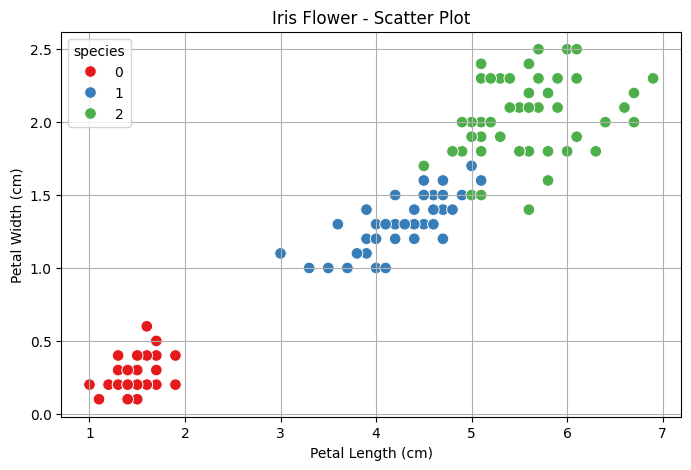

In [4]:
# ==========================================
# STEP 4.1: SCATTER PLOT
# ==========================================

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species",
    palette="Set1",
    s=70
)

plt.title("Iris Flower - Scatter Plot")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.grid(True)

plt.show()

/tmp/ipykernel_1017/1726002509.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


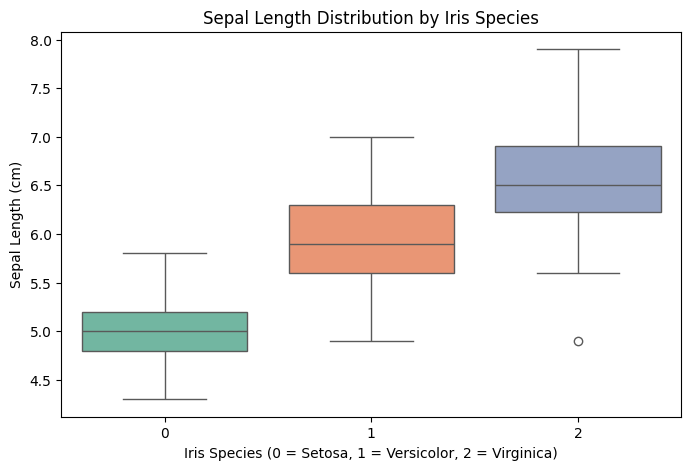

In [5]:
# ==========================================
# STEP 4.2: BOX PLOT
# ==========================================

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="species",
    y="sepal length (cm)",
    palette="Set2"
)

plt.title("Sepal Length Distribution by Iris Species")
plt.xlabel("Iris Species (0 = Setosa, 1 = Versicolor, 2 = Virginica)")
plt.ylabel("Sepal Length (cm)")

plt.show()

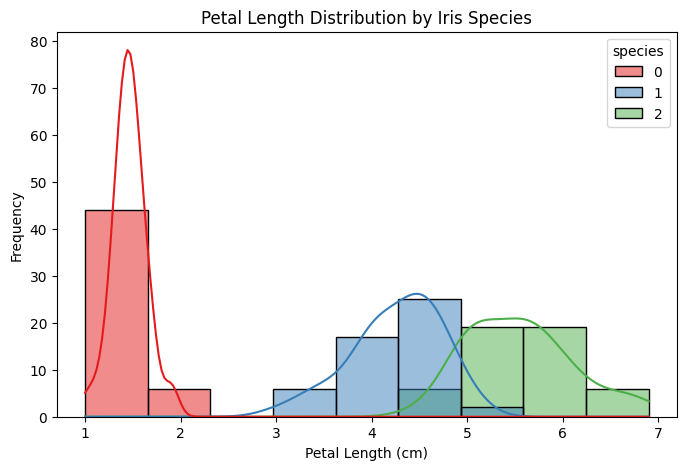

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="petal length (cm)",
    hue="species",
    kde=True,
    palette="Set1"
)

plt.title("Petal Length Distribution by Iris Species")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Frequency")
plt.show()

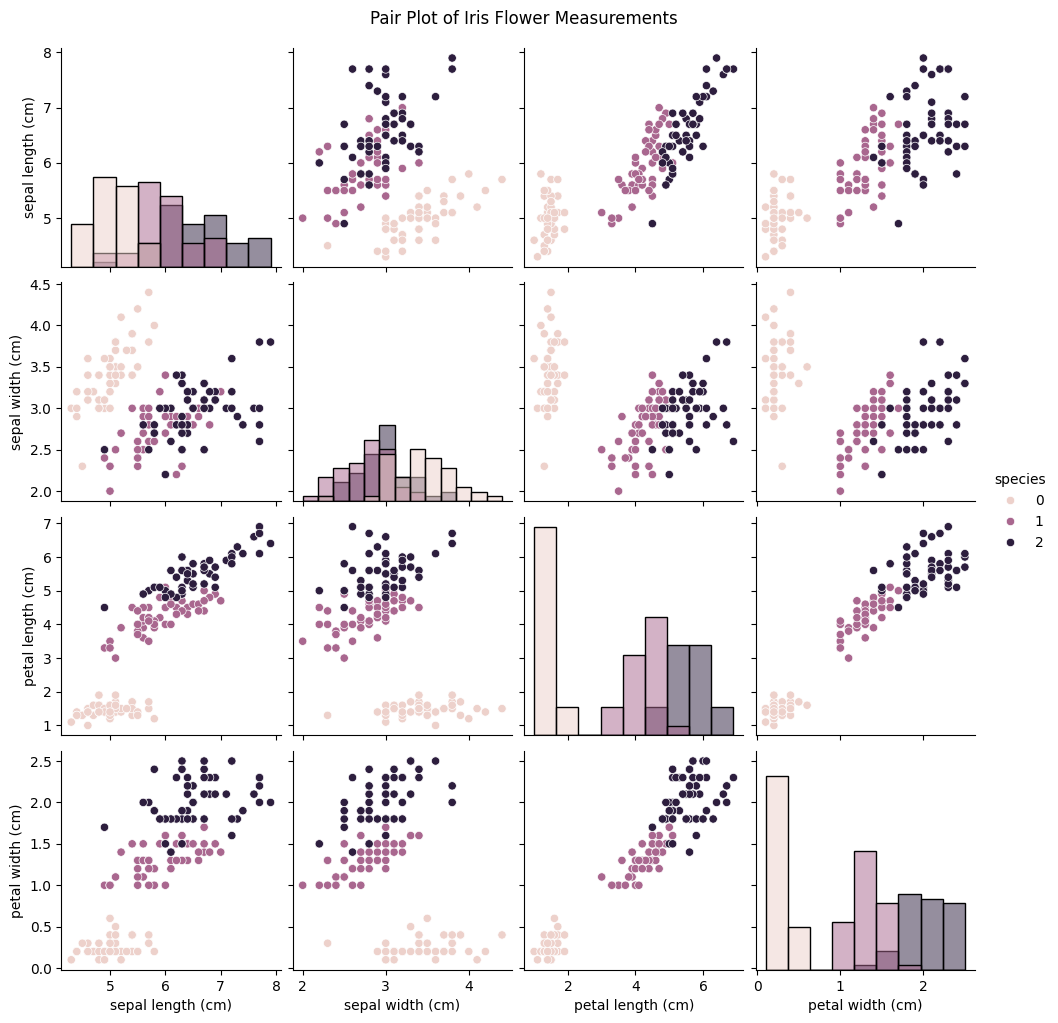

In [7]:
sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Pair Plot of Iris Flower Measurements", y=1.02)
plt.show()

In [8]:
# Separate input features and target variable

X = df[iris.feature_names]
y = iris.target

# Split dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training data records:", len(X_train))
print("Testing data records:", len(X_test))

print("\nTraining features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTrain-test split completed successfully!")

Training data records: 120
Testing data records: 30

Training features shape: (120, 4)
Testing features shape: (30, 4)

Train-test split completed successfully!


In [9]:
# Create Logistic Regression model using a Pipeline

model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=200))
])

# Train the model using training data

model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [10]:
# Predict flower species using testing data

predictions = model.predict(X_test)

# Calculate model accuracy

accuracy = accuracy_score(y_test, predictions)

print("LOGISTIC REGRESSION MODEL EVALUATION")
print("-----------------------------------")

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100)

# Display classification report

print("\nCLASSIFICATION REPORT:")

print(
    classification_report(
        y_test,
        predictions,
        target_names=iris.target_names
    )
)

LOGISTIC REGRESSION MODEL EVALUATION
-----------------------------------
Model Accuracy: 0.9333333333333333
Accuracy Percentage: 93.33333333333333

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [11]:
# Create Random Forest Classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train Random Forest model

rf_model.fit(X_train, y_train)

# Make predictions using testing data

rf_predictions = rf_model.predict(X_test)

# Calculate Random Forest accuracy

rf_accuracy = accuracy_score(y_test, rf_predictions)

# Compare both models

print("MODEL COMPARISON")
print("-----------------------------")

print("Logistic Regression Accuracy:", accuracy)
print("Random Forest Accuracy:", rf_accuracy)

print("\nLogistic Regression Percentage:", accuracy * 100)
print("Random Forest Percentage:", rf_accuracy * 100)

# Select the model with higher accuracy

best_model = model if accuracy >= rf_accuracy else rf_model

print("\nBest Model:",
      "Logistic Regression" if accuracy >= rf_accuracy
      else "Random Forest")

print("\nModel training and comparison completed successfully!")

MODEL COMPARISON
-----------------------------
Logistic Regression Accuracy: 0.9333333333333333
Random Forest Accuracy: 0.9

Logistic Regression Percentage: 93.33333333333333
Random Forest Percentage: 90.0

Best Model: Logistic Regression

Model training and comparison completed successfully!


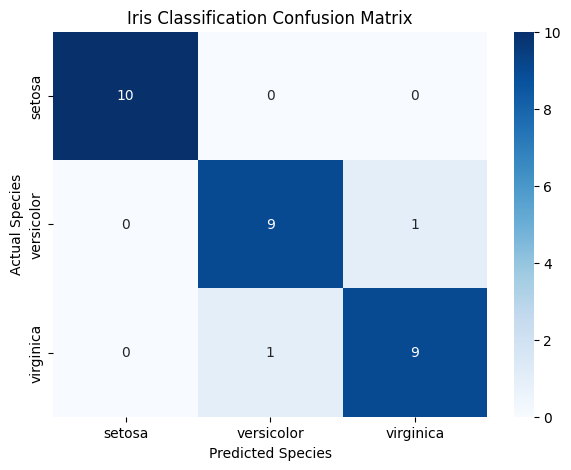

Confusion Matrix created successfully!


In [12]:
# Make predictions using the best model

best_predictions = best_model.predict(X_test)

# Create confusion matrix

cm = confusion_matrix(y_test, best_predictions)

# Visualize confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Iris Classification Confusion Matrix")

plt.show()

print("Confusion Matrix created successfully!")

In [13]:
# Save the best trained model

joblib.dump(best_model, "iris_model.pkl")

print("Best model saved successfully!")
print("File name: iris_model.pkl")

Best model saved successfully!
File name: iris_model.pkl


In [14]:
import os

print("Model file exists:", os.path.exists("iris_model.pkl"))
print("Saved file size:", os.path.getsize("iris_model.pkl"), "bytes")

Model file exists: True
Saved file size: 1889 bytes


In [15]:
from google.colab import files

files.download("iris_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>